In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv('data/CC_Customer_Dataset.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [7]:
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
X=df.iloc[:, 2:7]

## Model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

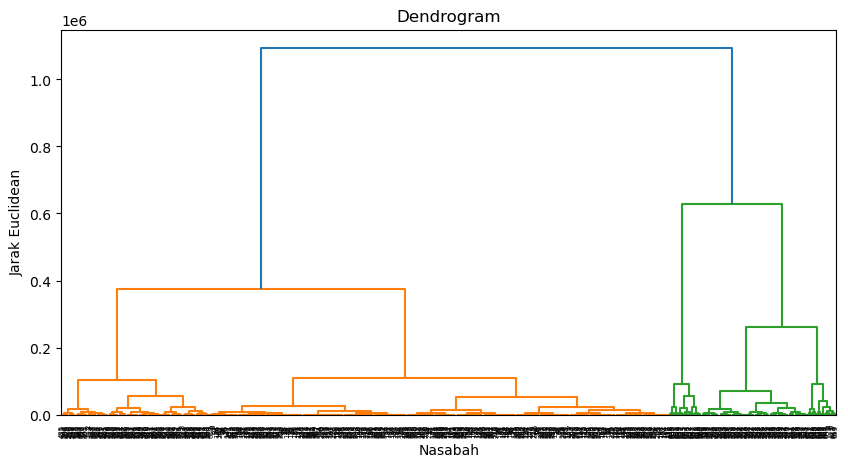

In [13]:
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Nasabah')
plt.ylabel('Jarak Euclidean')
plt.show()

## Scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

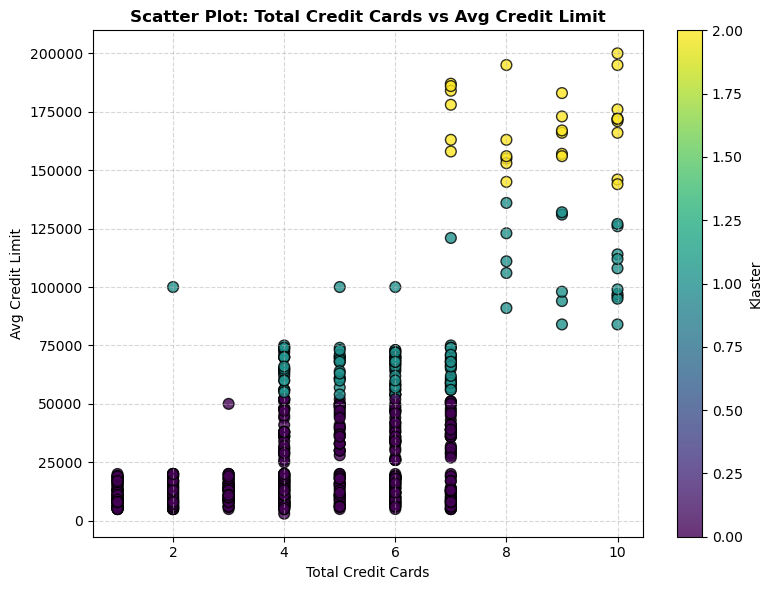

In [18]:
import seaborn as sns

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], c=y_hc, cmap='viridis', alpha=0.8, edgecolors='k', s=60)
plt.title('Scatter Plot: Total Credit Cards vs Avg Credit Limit', fontsize=12, fontweight='bold')
plt.xlabel('Total Credit Cards', fontsize=10)
plt.ylabel('Avg Credit Limit', fontsize=10)
plt.colorbar(scatter, label='Klaster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Silhouette score

In [19]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(X, y_hc)
print(f'Silhouette Coefficient: {silhouette_avg}')

Silhouette Coefficient: 0.6811232268244817


## DBI 

In [21]:
from sklearn.metrics import davies_bouldin_score

dbi = davies_bouldin_score(X, y_hc)
print(f"Nilai Davies-Bouldin Index: {dbi}")

Nilai Davies-Bouldin Index: 0.38800576073929305
